# Wine Quality — Classification & Regression / Phân loại và hồi quy

**Trương Minh Hoàng · MSSV 25410008 · UIT team coursework**

Đợt chạy mới kế thừa bài nhóm và sửa cách đánh giá: 11 đặc trưng hóa lý, nhãn `quality >= 6`,
nhóm các vector đặc trưng trùng để không nằm ở hai phía của phép chia. Chọn mô hình bằng
cross-validation trên train, sau đó mở holdout một lần. Phần hồi quy có bước huấn luyện và dự đoán đầy đủ.

This is a fresh, separately specified reproduction, not a recreation of the exact historical team scores.
Data: [UCI Wine Quality](https://archive.ics.uci.edu/dataset/186/wine+quality), CC BY 4.0, Cortez et al. (2009).
Run `pip install -r requirements.txt` from this project folder before running all cells.

In [1]:
from pathlib import Path
import os, sys, json
ROOT = Path.cwd()
if ROOT.name == 'notebooks': ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from wine_quality import load_wine, grouped_split, run_classification, run_regression
data, features, data_hashes = load_wine(os.environ.get('WINE_DATA_DIR', str(ROOT/'data/local')))
print('Samples:',len(data),'Physicochemical features:',len(features))
display(data.groupby('wine_type').agg(samples=('quality','size'), mean_quality=('quality','mean')))
assert set(features).isdisjoint({'quality','label','wine_type'})


Samples: 6497 Physicochemical features: 11


,samples,mean_quality
wine_type,,
red,1599,5.636023
white,4898,5.877909


## 1. Khám phá dữ liệu / EDA
Không có cột nhãn trong ma trận đầu vào. Các hình dưới đây mô tả toàn bộ bộ dữ liệu, không dùng để chọn model.

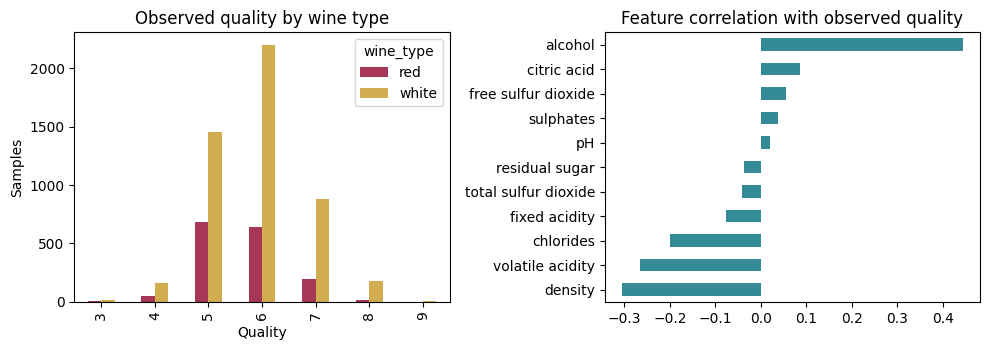

In [2]:
fig, ax=plt.subplots(1,2,figsize=(10,3.6))
pd.crosstab(data.quality,data.wine_type).plot.bar(ax=ax[0],color=['#a63757','#d1ad50'])
ax[0].set_title('Observed quality by wine type');ax[0].set_xlabel('Quality');ax[0].set_ylabel('Samples')
data[features+['quality']].corr()['quality'].drop('quality').sort_values().plot.barh(ax=ax[1],color='#348b97')
ax[1].set_title('Feature correlation with observed quality')
fig.tight_layout();plt.show()


## 2. Chia nhóm trùng / Duplicate-aware split
Giữ toàn bộ dòng gốc; các vector 11 đặc trưng giống nhau vào cùng nhóm, kể cả khi có nhãn khác nhau. Holdout là fold đầu của StratifiedGroupKFold 5 folds, seed 42. Tỷ lệ xấp xỉ 80/20.

In [3]:
train,test,groups=grouped_split(data,features)
split_audit={'rows':len(data),'unique_feature_groups':len(set(groups)),
 'train_rows':len(train),'test_rows':len(test),
 'group_overlap':len(set(groups[train])&set(groups[test])),
 'train_positive_rate':float((data.quality.iloc[train]>=6).mean()),
 'test_positive_rate':float((data.quality.iloc[test]>=6).mean())}
display(pd.Series(split_audit))
assert split_audit['group_overlap']==0


rows                     6497.000000
unique_feature_groups    5318.000000
train_rows               5198.000000
test_rows                1299.000000
group_overlap               0.000000
train_positive_rate         0.632936
test_positive_rate          0.633564
dtype: float64

## 3. Phân loại / Classification
Logistic Regression, Decision Tree, LightGBM và XGBoost có cấu hình cố định. Ba fold trên train chọn theo macro F1; chuẩn hóa/điền thiếu được fit bên trong từng pipeline. Bảng holdout chỉ dùng để báo cáo sau khi khóa lựa chọn.

In [4]:
classification_cv,classification_test,classification_winner,classifiers=run_classification(data,features,train,test,groups)
display(classification_cv.drop(columns='fold_scores'))
print('Selected using train CV:',classification_winner)
display(classification_test.drop(columns='confusion_matrix').round(5))


,model,cv_macro_f1_mean,cv_macro_f1_std
2,LightGBM,0.750612,0.006497
3,XGBoost,0.741751,0.006175
0,Logistic Regression,0.711069,0.005341
1,Decision Tree,0.704248,0.016299


Selected using train CV: LightGBM


,model,accuracy,precision,recall,f1,macro_f1,roc_auc
0,Logistic Regression,0.72902,0.76254,0.83111,0.79535,0.69722,0.77786
1,Decision Tree,0.71978,0.77684,0.78250,0.77966,0.69744,0.76431
2,LightGBM,0.74288,0.78397,0.82017,0.80166,0.71812,0.80085
3,XGBoost,0.74365,0.78422,0.82139,0.80237,0.71882,0.80170


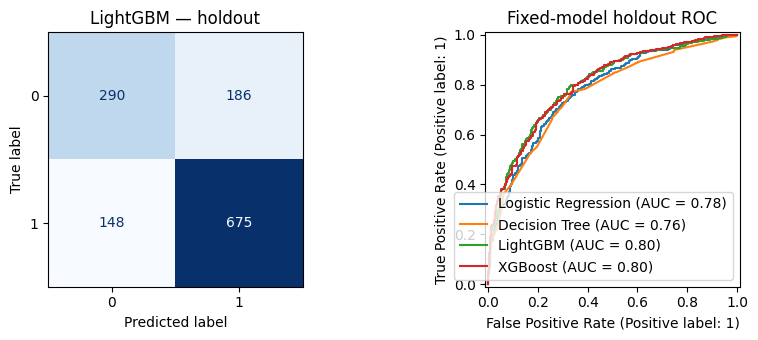

In [5]:
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay
fig,ax=plt.subplots(1,2,figsize=(9,3.5))
model=classifiers[classification_winner]
y_test=(data.quality.iloc[test]>=6).astype(int)
ConfusionMatrixDisplay.from_estimator(model,data[features].iloc[test],y_test,ax=ax[0],colorbar=False,cmap='Blues')
ax[0].set_title(classification_winner+' — holdout')
for name,model in classifiers.items(): RocCurveDisplay.from_estimator(model,data[features].iloc[test],y_test,ax=ax[1],name=name)
ax[1].set_title('Fixed-model holdout ROC');fig.tight_layout();plt.show()


## 4. Hồi quy / Regression
Ridge và Random Forest dự đoán điểm quality gốc. GroupKFold 3 folds trên cùng train chọn theo RMSE. Dùng cùng holdout và nhóm trùng như bài phân loại; mọi `y_pred` được tạo từ mô hình đã fit.

In [6]:
regression_cv,regression_test,regression_winner,regression_predictions=run_regression(data,features,train,test,groups)
display(regression_cv.round(5))
print('Selected using train CV:',regression_winner)
display(regression_test.round(5))


,model,cv_rmse_mean,cv_rmse_std
0,Ridge,0.73270,0.01095
1,Random Forest,0.68628,0.00855


Selected using train CV: Random Forest


,model,rmse,mae,r2
0,Ridge,0.75447,0.58768,0.26801
1,Random Forest,0.70782,0.53924,0.35574


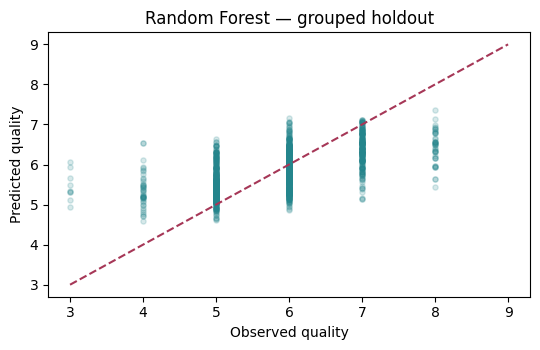

In [7]:
fig,ax=plt.subplots(figsize=(5.5,3.6))
actual=data.quality.iloc[test].to_numpy();pred=regression_predictions[regression_winner]
ax.scatter(actual,pred,alpha=.18,s=14,color='#24858c')
ax.plot([3,9],[3,9],color='#a63757',linestyle='--')
ax.set(xlabel='Observed quality',ylabel='Predicted quality',title=regression_winner+' — grouped holdout')
fig.tight_layout();plt.show()
assert np.isfinite(pred).all()


## 5. Bằng chứng và giới hạn / Evidence and limits
Bảng CV quyết định lựa chọn mô hình; các kết quả holdout không được dùng để sửa cấu hình trong đợt này. Nhóm các dòng trùng chưa thay thế được thông tin winery/batch mà UCI không cung cấp. Không so sánh trực tiếp số mới với số nhóm cũ khi cách chia khác nhau.

In [8]:
from datetime import datetime, timezone
LAB_RESULT={'status':'PASS','scope':'fresh grouped-holdout reproduction','seed':42,
 'data_sha256':data_hashes,'split':split_audit,
 'classification_cv':classification_cv.to_dict('records'),
 'classification_test':classification_test.to_dict('records'),'classification_selected':classification_winner,
 'regression_cv':regression_cv.to_dict('records'),'regression_test':regression_test.to_dict('records'),
 'regression_selected':regression_winner,'threshold':0.5,
 'completed_at_utc':datetime.now(timezone.utc).isoformat()}
(ROOT/'evidence').mkdir(exist_ok=True)
(ROOT/'evidence/reproduction.json').write_text(json.dumps(LAB_RESULT,indent=2,ensure_ascii=False)+'\n')
print('Saved evidence/reproduction.json')


Saved evidence/reproduction.json
